# Shallow3再評価と、見逃し・過剰検知画像の確認

保存済みの **VAE_CNN_Shallow3（浅い3層CNN）** を再評価します。再学習は行いません。

- 前処理・SSIM Top-130・モデル構造は、7/9の評価ノートブックと同じです。
- 今回はCPU、乱数シード42、画像パス順を固定します。潜在変数は過去と同じくサンプリングします。過去のAUROC 0.9722と一致するとは限りません。
- 性能比較の指標は **AUROCのみ**。見逃し・過剰検知の画像確認のため、別途固定閾値を使います。
- 初期閾値 **0.7934** は7/9の保存済み出力にある小数4桁の値。当時は同じテストのF1最大化で選ばれており、独立な検証データで決めた閾値ではありません。今回は再最適化しません。
- 判定は過去と同じく **スコア > 閾値なら異常、等しければ正常**です。
- **評価時の入力・復元・マップを保持**し、その配列だけで誤判定画像を描画します。表示時に再推論しません。

上から順に「すべて実行」してください。閾値だけを変える場合は、設定セルのTHRESHOLDを変更し、「3. 固定閾値で判定」以降を実行すると、同じ復元結果で確認できます。

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import platform
import importlib.metadata
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import transforms
from PIL import Image
from skimage.metrics import structural_similarity as ssim
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

%matplotlib inline

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'code' / '260709AUROCを用いた比較評価.ipynb').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('このリポジトリ内を作業ディレクトリにしてください。')

THRESHOLD = 0.7934  # 変更後は「3. 固定閾値で判定」以降を再実行。
TOP_K = 130
SEED = 42
DEVICE = torch.device('cpu')
ROWS_PER_FIGURE = 3
MODEL_PATH = ROOT / 'saved_models' / 'vae_CNN_Shallow3_Annealing_ep100_beta50_128.pth'
TEST_DIR = ROOT / 'data' / 'bottle' / 'test'
torch.set_num_threads(min(4, max(1, torch.get_num_threads())))
torch.use_deterministic_algorithms(True)

fonts = {f.name for f in font_manager.fontManager.ttflist}
for font in ['Yu Gothic', 'Meiryo', 'MS Gothic', 'Noto Sans CJK JP', 'IPAexGothic']:
    if font in fonts:
        plt.rcParams['font.family'] = font
        break
else:
    import japanize_matplotlib
plt.rcParams.update({'font.size': 11, 'axes.unicode_minus': False, 'figure.dpi': 100})
CATEGORY_NAMES = {'good': '正常', 'broken_large': '大きな破損',
                  'broken_small': '小さな破損', 'contamination': '汚れ・異物'}

# scikit-learnの一部DLLがこのWindows環境でブロックされるため、
# 標準的な経験ROCとその台形積分をNumPyで計算する。
# 同点スコアは必ずまとめて扱う。
def binary_roc_curve(y_true, scores):
    labels = np.asarray(y_true)
    scores = np.asarray(scores, dtype=float)
    if labels.ndim != 1 or scores.ndim != 1 or labels.shape != scores.shape:
        raise ValueError('ラベルとスコアは同じ長さの1次元配列にしてください。')
    if not np.isfinite(scores).all() or not np.isin(labels, [0, 1]).all():
        raise ValueError('スコアは有限値、ラベルは0または1である必要があります。')
    positives = int((labels == 1).sum())
    negatives = int((labels == 0).sum())
    if not positives or not negatives:
        raise ValueError('正常と異常の両方が必要です。')
    order = np.argsort(-scores, kind='stable')
    ordered_scores = scores[order]
    ordered_labels = labels[order]
    ends = np.r_[np.flatnonzero(np.diff(ordered_scores)), len(scores) - 1]
    true_positives = np.cumsum(ordered_labels)[ends]
    false_positives = (ends + 1) - true_positives
    fpr = np.r_[0.0, false_positives / negatives]
    tpr = np.r_[0.0, true_positives / positives]
    thresholds = np.r_[np.inf, ordered_scores[ends]]
    return fpr, tpr, thresholds

def binary_auroc(y_true, scores):
    fpr, tpr, _ = binary_roc_curve(y_true, scores)
    return float(np.trapezoid(tpr, fpr))

# 完全分離・逆順位・全同点の基本例を確認。
assert binary_auroc([0, 0, 1, 1], [0.1, 0.2, 0.8, 0.9]) == 1.0
assert binary_auroc([0, 0, 1, 1], [0.9, 0.8, 0.2, 0.1]) == 0.0
assert binary_auroc([0, 0, 1, 1], [0.5, 0.5, 0.5, 0.5]) == 0.5


## 1. 保存済みモデルの読み込み

モデルのクラス定義は7/9のノートブックから転記しています。evalモードでも潜在変数はサンプリングされます。推論直前に乱数を固定します。

前処理：中央820×820を切り出す → 128×128へLANCZOS縮小 → グレースケール → 0〜1のテンソル。

In [2]:
class VAE_CNN_Shallow3(nn.Module):
    """
    浅い3層の畳み込み層を用いた軽量VAEモデル
    """
    def __init__(self, latent_dim=64):
        super(VAE_CNN_Shallow3, self).__init__()

        # --- エンコーダ: 畳み込み層で空間情報を保ちながら圧縮 (128 -> 64 -> 32 -> 16) ---
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )

        # 64チャンネル * 16 * 16 = 16384次元
        self.fc_mu = nn.Linear(64 * 16 * 16, latent_dim)
        self.fc_logvar = nn.Linear(64 * 16 * 16, latent_dim)

        self.decoder_fc = nn.Linear(latent_dim, 64 * 16 * 16)

        # --- デコーダ: 逆畳み込み層で元の画像サイズへ復元 ---
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),

            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        h = self.encoder_conv(x)
        h = torch.flatten(h, start_dim=1)

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        # 潜在変数の発散(KLD爆発)を防ぐ安全装置
        logvar = torch.clamp(logvar, min=-10.0, max=10.0)

        std = torch.exp(0.5 * logvar)
        z = mu + torch.randn_like(std) * std

        h_recon = self.decoder_fc(z)
        h_recon = h_recon.view(-1, 64, 16, 16) 
        recon = self.decoder_conv(h_recon)

        return recon, mu, logvar

transform = transforms.Compose([
    transforms.CenterCrop(820),
    transforms.Resize((128, 128), interpolation=transforms.InterpolationMode.LANCZOS),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])
if not MODEL_PATH.is_file():
    raise FileNotFoundError(f'重みが見つかりません: {MODEL_PATH}')
if not TEST_DIR.is_dir():
    raise FileNotFoundError(TEST_DIR)
model = VAE_CNN_Shallow3(latent_dim=64).to(DEVICE)
state_dict = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True)
model.load_state_dict(state_dict, strict=True)
model.eval()
print(f'重み: {MODEL_PATH.relative_to(ROOT)}')
print(f'SHA-256: {hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()}')
print(f'デバイス: {DEVICE} / 潜在次元: 64 / seed: {SEED}')

重み: saved_models\vae_CNN_Shallow3_Annealing_ep100_beta50_128.pth
SHA-256: 1aec6598aabd5f57593071e8c481038549a6b8d1677ecb11ed170294b44759f5
デバイス: cpu / 潜在次元: 64 / seed: 42


## 2. 全画像を一度だけ評価する

SSIMのマップ（局所窓11×11）から「1 − SSIM」を計算し、平坦化した値の**上位130点の平均**を画像の異常スコアにします。独立した130個のパッチを切り出す処理ではありません。

入力・復元・異常度マップをメモリに保持し、後の画像表示に使います。

In [3]:
paths = sorted(TEST_DIR.glob('*/*.png'), key=lambda p: p.relative_to(TEST_DIR).as_posix())
if not paths:
    raise ValueError('評価画像がありません。')
if any(p.parent.name not in CATEGORY_NAMES for p in paths):
    raise ValueError('未定義のカテゴリがあります。')
if not any(p.parent.name == 'good' for p in paths) or not any(p.parent.name != 'good' for p in paths):
    raise ValueError('AUROCの計算には正常と異常の両方が必要です。')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
records, image_cache = [], {}
dataset_digest = hashlib.sha256()
with torch.inference_mode():
    for i, path in enumerate(paths, 1):
        rel = path.relative_to(TEST_DIR).as_posix()
        raw = path.read_bytes()
        file_hash = hashlib.sha256(raw).hexdigest()
        dataset_digest.update(rel.encode('utf-8') + b'\0' + file_hash.encode('ascii') + b'\n')
        with Image.open(BytesIO(raw)) as im:
            x = transform(im.convert('RGB')).unsqueeze(0).to(DEVICE)
        recon, _, _ = model(x)
        input_img = x[0, 0].cpu().numpy().copy()
        recon_img = recon[0, 0].cpu().numpy().copy()
        _, smap = ssim(input_img, recon_img, data_range=1.0, win_size=11, full=True)
        anomaly_map = 1.0 - smap
        if not 1 <= TOP_K <= anomaly_map.size or not np.isfinite(anomaly_map).all():
            raise ValueError(f'TOP_Kまたは異常度マップを確認してください: {rel}')
        score = float(np.mean(np.sort(anomaly_map.ravel())[::-1][:TOP_K]))
        records.append({'relative_path': rel, 'category': path.parent.name,
                        'category_ja': CATEGORY_NAMES[path.parent.name],
                        'true_label': int(path.parent.name != 'good'),
                        'score': score, 'file_sha256': file_hash})
        image_cache[rel] = {'input': input_img, 'reconstruction': recon_img, 'anomaly_map': anomaly_map}
        if i % 20 == 0 or i == len(paths):
            print(f'評価済み: {i}/{len(paths)}枚')

results = pd.DataFrame(records)
assert len(results) == len(image_cache) == len(paths) and results.relative_path.is_unique
auroc = float(binary_auroc(results.true_label, results.score))
evaluation_info = {
    'model': MODEL_PATH.relative_to(ROOT).as_posix(),
    'model_sha256': hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest(),
    'dataset_manifest_sha256': dataset_digest.hexdigest(),
    'image_counts': {str(k): int(v) for k, v in results.category.value_counts().sort_index().items()},
    'device': str(DEVICE), 'seed': SEED, 'threads': torch.get_num_threads(),
    'inference': 'posterior sampling, one sample per image, sorted paths',
    'top_k': TOP_K, 'ssim_window': 11, 'ssim_data_range': 1.0, 'auroc': auroc,
    'versions': {'python': platform.python_version(), **{
        package: importlib.metadata.version(package)
        for package in ['torch', 'torchvision', 'numpy', 'scikit-image', 'scikit-learn', 'Pillow']
    }},
}
display(Markdown(f'### 今回のAUROC：**{auroc:.4f}**\n\n評価画像：{len(results)}枚'
                 f'（正常{int((results.true_label == 0).sum())}枚・'
                 f'異常{int((results.true_label == 1).sum())}枚）'))
print(json.dumps(evaluation_info, ensure_ascii=False, indent=2))

評価済み: 20/83枚


評価済み: 40/83枚


評価済み: 60/83枚


評価済み: 80/83枚
評価済み: 83/83枚


### 今回のAUROC：**0.9698**

評価画像：83枚（正常20枚・異常63枚）

{
  "model": "saved_models/vae_CNN_Shallow3_Annealing_ep100_beta50_128.pth",
  "model_sha256": "1aec6598aabd5f57593071e8c481038549a6b8d1677ecb11ed170294b44759f5",
  "dataset_manifest_sha256": "419baa5e608bd0d1a478939e8602e02bd60cc93a10821aa6a8c1828e0e4901c9",
  "image_counts": {
    "broken_large": 20,
    "broken_small": 22,
    "contamination": 21,
    "good": 20
  },
  "device": "cpu",
  "seed": 42,
  "threads": 4,
  "inference": "posterior sampling, one sample per image, sorted paths",
  "top_k": 130,
  "ssim_window": 11,
  "ssim_data_range": 1.0,
  "auroc": 0.9698412698412698,
  "versions": {
    "python": "3.13.14",
    "torch": "2.12.0",
    "torchvision": "0.27.0",
    "numpy": "2.4.6",
    "scikit-image": "0.26.0",
    "scikit-learn": "1.9.0",
    "Pillow": "12.2.0"
  }
}


## 3. 固定閾値で判定し、ROC曲線とスコア分布を確認する

**AUROCには閾値を使いません。** 見逃し・過剰検知の区分は、画像を調べるために固定閾値を使った結果です。

この環境ではscikit-learnの一部DLLがWindowsの制御で読み込めないため、NumPyで経験ROCを作り、台形積分でAUROCを計算します。同点スコアはまとめて扱います。AUROCの定義は変えず、順位による別計算とも照合しています。

図の書式は260719新しいモデルによる検証.ipynbに合わせています。ROC曲線はオレンジ色の独立した図、スコア分布は正常＝緑・異常＝赤のヒストグラム（共通のビン境界40点）とし、青い破線で固定閾値を表示します。

**固定閾値：0.7934**（スコアがこれより大きければ異常）

- 見逃し：**3枚**
- 過剰検知：**5枚**

件数は画像確認のための集計です。性能比較にはAUROCを使います。

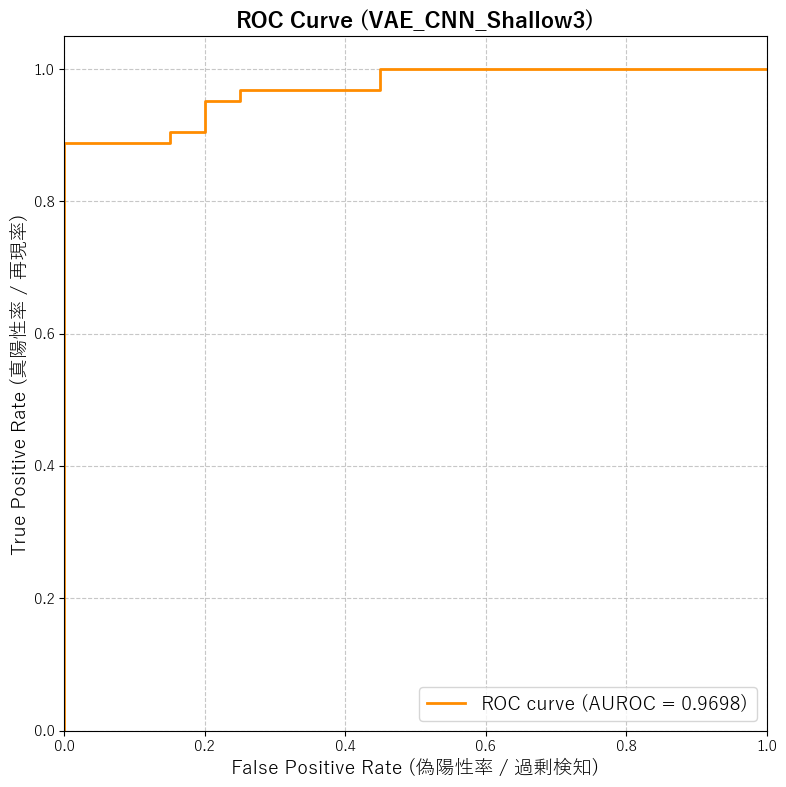

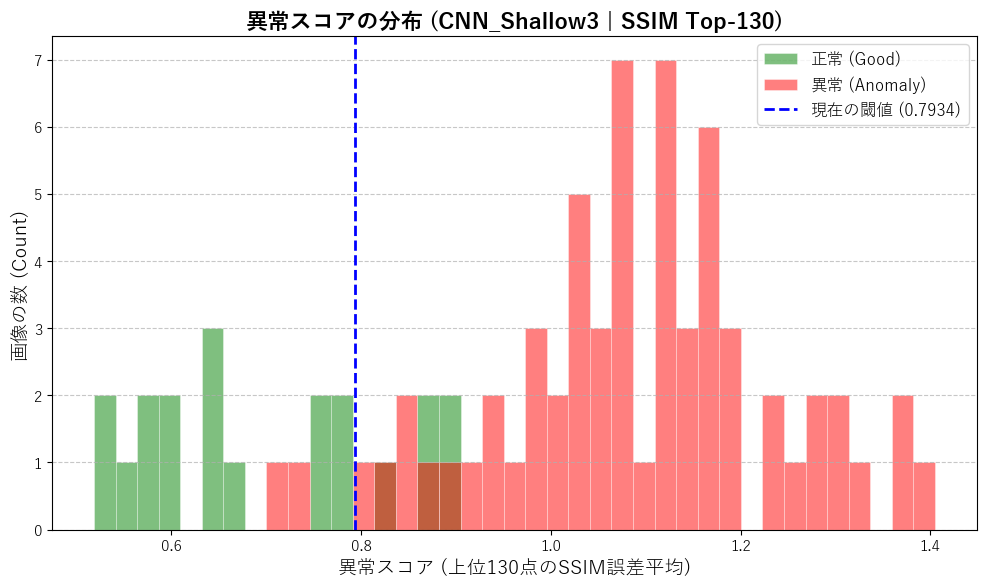

In [4]:
if not np.isfinite(THRESHOLD):
    raise ValueError('閾値には有限な数値を指定してください。')
results['pred_label'] = (results.score > THRESHOLD).astype(int)
results['threshold'] = float(THRESHOLD)
results['margin'] = results.score - THRESHOLD
results['outcome'] = np.select([
    (results.true_label == 1) & (results.pred_label == 0),
    (results.true_label == 0) & (results.pred_label == 1),
    (results.true_label == 0) & (results.pred_label == 0),
], ['FN: 見逃し', 'FP: 過剰検知', 'TN: 正常を正常と判定'], default='TP: 異常を異常と判定')
fn_rows = results[results.outcome == 'FN: 見逃し'].sort_values(['score', 'relative_path'])
fp_rows = results[results.outcome == 'FP: 過剰検知'].sort_values(
    ['score', 'relative_path'], ascending=[False, True])
display(Markdown(
    f'**固定閾値：{THRESHOLD:.4f}**（スコアがこれより大きければ異常）\n\n'
    f'- 見逃し：**{len(fn_rows)}枚**\n- 過剰検知：**{len(fp_rows)}枚**\n\n'
    '件数は画像確認のための集計です。性能比較にはAUROCを使います。'))


# 260719新しいモデルによる検証.ipynbに合わせた、独立した2つの図。
# AUROC・スコア・判定は上で計算済みの値をそのまま使用する。
model_name = 'VAE_CNN_Shallow3'
fpr, tpr, _ = binary_roc_curve(results.true_label, results.score)
fig_roc, ax_roc = plt.subplots(figsize=(8, 8))
ax_roc.plot(fpr, tpr, color='darkorange', lw=2,
            label=f'ROC curve (AUROC = {auroc:.4f})')
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel('False Positive Rate (偽陽性率 / 過剰検知)', fontsize=14)
ax_roc.set_ylabel('True Positive Rate (真陽性率 / 再現率)', fontsize=14)
ax_roc.set_title(f'ROC Curve ({model_name})', fontsize=16, fontweight='bold')
ax_roc.legend(loc='lower right', fontsize=14)
ax_roc.grid(True, linestyle='--', alpha=0.7)
fig_roc.tight_layout()
plt.show()
plt.close(fig_roc)

normal_scores = results.loc[results.true_label == 0, 'score'].to_numpy()
anomaly_scores = results.loc[results.true_label == 1, 'score'].to_numpy()
common_bins = np.linspace(results.score.min(), results.score.max(), 40)
fig_hist, ax_hist = plt.subplots(figsize=(10, 6))
# Matplotlibで、参考元のhistplotと同じビン・色・透明度の件数ヒストグラムを描く。
ax_hist.hist(normal_scores, bins=common_bins, color='green', alpha=0.5,
             edgecolor='white', linewidth=0.5, label='正常 (Good)')
ax_hist.hist(anomaly_scores, bins=common_bins, color='red', alpha=0.5,
             edgecolor='white', linewidth=0.5, label='異常 (Anomaly)')
ax_hist.axvline(x=THRESHOLD, color='blue', linestyle='--', linewidth=2,
                label=f'現在の閾値 ({THRESHOLD:.4f})')
ax_hist.set_title(f'異常スコアの分布 (CNN_Shallow3 | SSIM Top-{TOP_K})',
                   fontsize=16, fontweight='bold')
ax_hist.set_xlabel(f'異常スコア (上位{TOP_K}点のSSIM誤差平均)', fontsize=14)
ax_hist.set_ylabel('画像の数 (Count)', fontsize=14)
ax_hist.legend(fontsize=12)
ax_hist.grid(axis='y', linestyle='--', alpha=0.7)
fig_hist.tight_layout()
plt.show()
plt.close(fig_hist)


## 4. 誤判定画像の表示方法

各行が1枚の画像です。**左：実際の入力／中央：評価時の復元／右：異常度マップ**を表示します。

- 入力・復元の明るさは0〜1に固定。異常度マップも全テスト画像で同じ色の尺度を使い、明るい色ほど差が大きい箇所です。
- マップの白い輪郭は、スコアに使った上位130点の位置。キズの正解位置ではありません。
- ファイル名、正解、モデル判定、スコア、閾値を行ごとに示します。
- 該当する**全画像**を3枚ずつに分けて表示し、0枚の場合も明記します。
- 以下の関数は保存済み配列だけを描画し、再推論しません。

In [5]:
MAP_VMAX = max(0.1, max(float(v['anomaly_map'].max()) for v in image_cache.values()))

def display_error_images(rows, title):
    display(Markdown(f'### {title}：{len(rows)}枚'))
    if rows.empty:
        display(Markdown('この固定閾値では、該当する画像はありません。'))
        return
    cols = ['relative_path', 'category_ja', 'score', 'threshold', 'margin', 'outcome']
    display(rows[cols].rename(columns={
        'relative_path': 'テスト内のファイル', 'category_ja': '実際の種類',
        'score': '異常スコア', 'threshold': '閾値', 'margin': 'スコア−閾値', 'outcome': '分類',
    }).style.format({'異常スコア': '{:.6f}', '閾値': '{:.4f}', 'スコア−閾値': '{:+.6f}'}))
    for start in range(0, len(rows), ROWS_PER_FIGURE):
        chunk = rows.iloc[start:start + ROWS_PER_FIGURE]
        fig, axes = plt.subplots(len(chunk), 3, figsize=(14, 4.5 * len(chunk)),
                                 squeeze=False, constrained_layout=True)
        fig.suptitle(f'{title}：{start + 1}〜{start + len(chunk)}枚目 / 全{len(rows)}枚',
                     fontsize=15, color='#9b3a3a')
        for j, row in enumerate(chunk.itertuples()):
            cached = image_cache[row.relative_path]
            flat = cached['anomaly_map'].ravel()
            assert np.isclose(row.score, np.mean(np.sort(flat)[::-1][:TOP_K]), atol=1e-7)
            indices = np.argsort(flat, kind='stable')[-TOP_K:]
            mask = np.zeros(flat.shape, dtype=np.uint8)
            mask[indices] = 1
            mask = mask.reshape(cached['anomaly_map'].shape)
            truth = '異常' if row.true_label else '正常'
            pred = '異常' if row.pred_label else '正常'
            left, middle, right = axes[j]
            left.imshow(cached['input'], cmap='gray', vmin=0, vmax=1)
            left.set_title(f'{row.relative_path}\n入力：{row.category_ja}（正解：{truth}）', fontsize=11)
            middle.imshow(cached['reconstruction'], cmap='gray', vmin=0, vmax=1)
            middle.set_title(f'評価時の復元画像\nモデルの判定：{pred}', fontsize=11)
            heat = right.imshow(cached['anomaly_map'], cmap='magma', vmin=0, vmax=MAP_VMAX)
            right.contour(mask, levels=[0.5], colors='white', linewidths=0.6)
            right.set_title(f'異常度マップ / 白線：上位{TOP_K}点\n'
                            f'スコア {row.score:.6f} / 閾値 {THRESHOLD:.4f}', fontsize=11)
            bar = fig.colorbar(heat, ax=right, fraction=0.046, pad=0.04)
            bar.set_label('1 − SSIM（全画像で共通の尺度）', fontsize=9)
            for ax in [left, middle, right]:
                ax.axis('off')
        plt.show()
        plt.close(fig)

## 5. 見逃し：実際は異常なのに「正常」と判断された画像

異常画像のうちスコアが閾値以下だった画像を、スコアが低い順にすべて表示します。

### 見逃し（異常 → 正常）：3枚

,テスト内のファイル,実際の種類,異常スコア,閾値,スコア−閾値,分類
61,contamination/019.png,汚れ・異物,0.704043,0.7934,-0.089357,FN: 見逃し
56,contamination/014.png,汚れ・異物,0.736868,0.7934,-0.056532,FN: 見逃し
45,contamination/003.png,汚れ・異物,0.792008,0.7934,-0.001392,FN: 見逃し


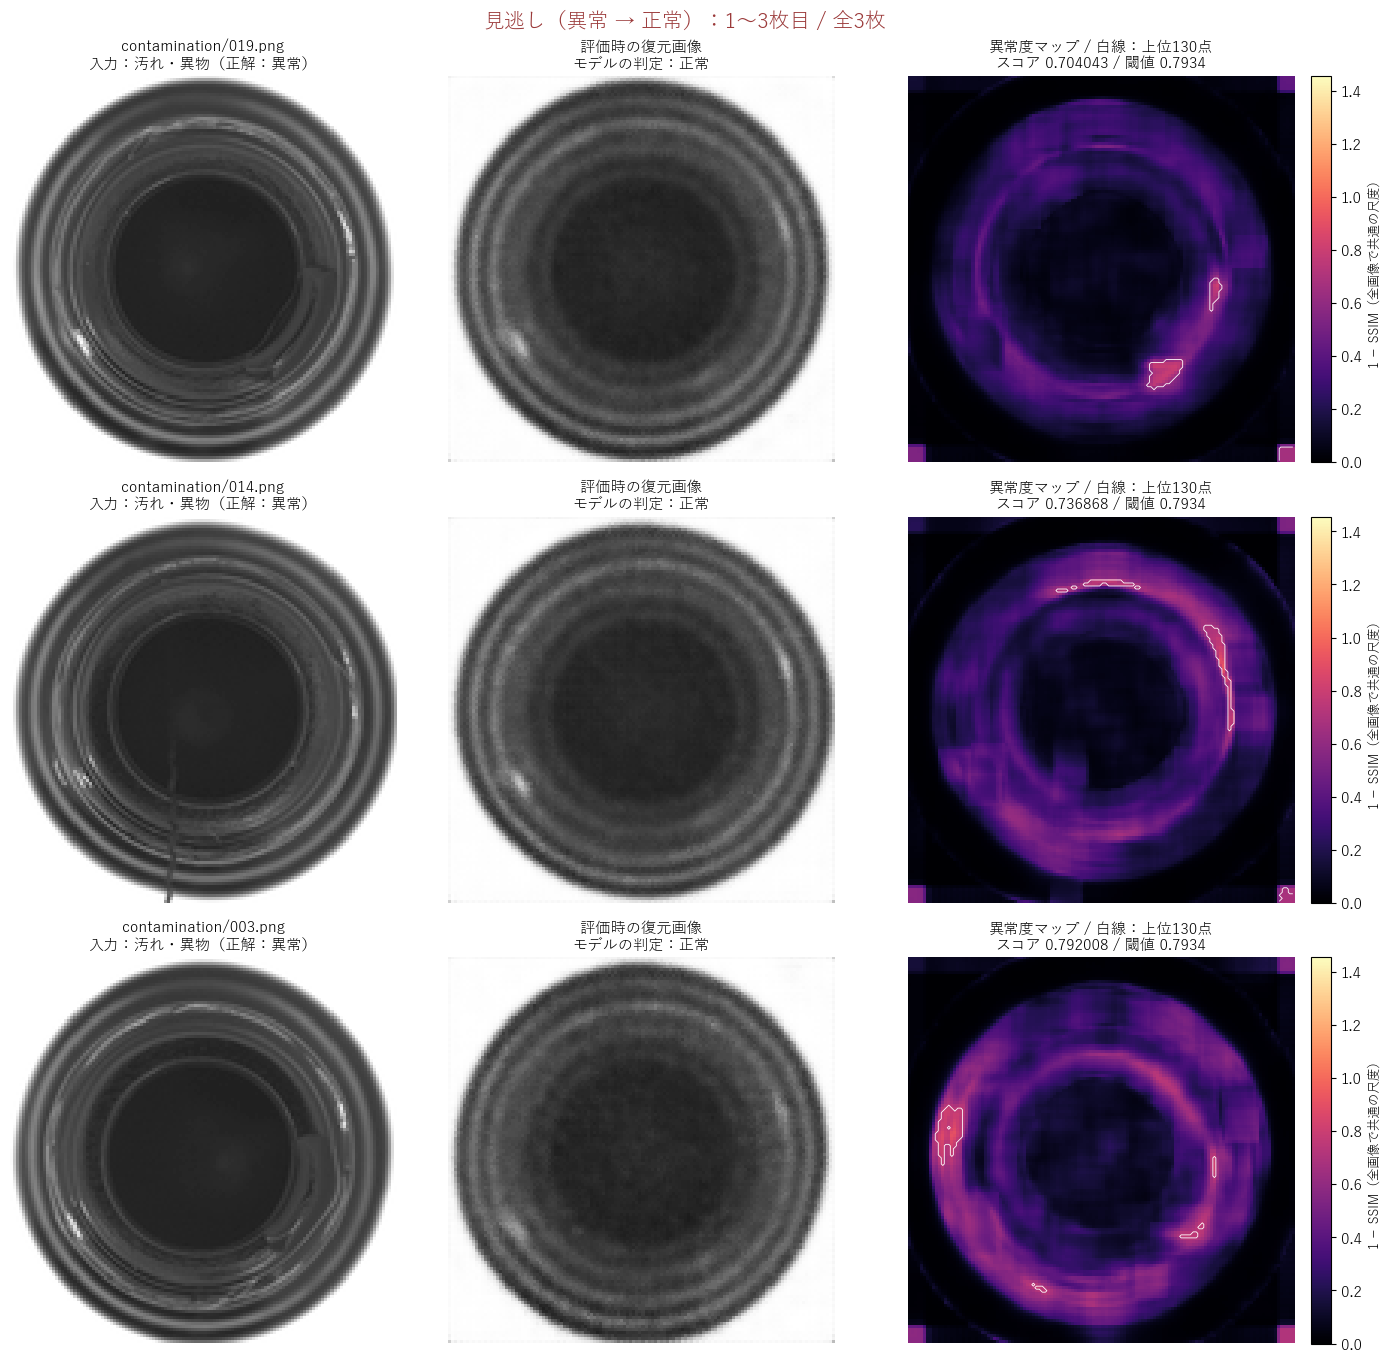

In [6]:
display_error_images(fn_rows, '見逃し（異常 → 正常）')

## 6. 過剰検知：実際は正常なのに「異常」と判断された画像

正常画像のうちスコアが閾値を超えた画像を、スコアが高い順にすべて表示します。

### 過剰検知（正常 → 異常）：5枚

,テスト内のファイル,実際の種類,異常スコア,閾値,スコア−閾値,分類
75,good/012.png,正常,0.893030,0.7934,+0.099630,FP: 過剰検知
70,good/007.png,正常,0.883368,0.7934,+0.089968,FP: 過剰検知
73,good/010.png,正常,0.881261,0.7934,+0.087861,FP: 過剰検知
81,good/018.png,正常,0.860932,0.7934,+0.067532,FP: 過剰検知
78,good/015.png,正常,0.822088,0.7934,+0.028688,FP: 過剰検知


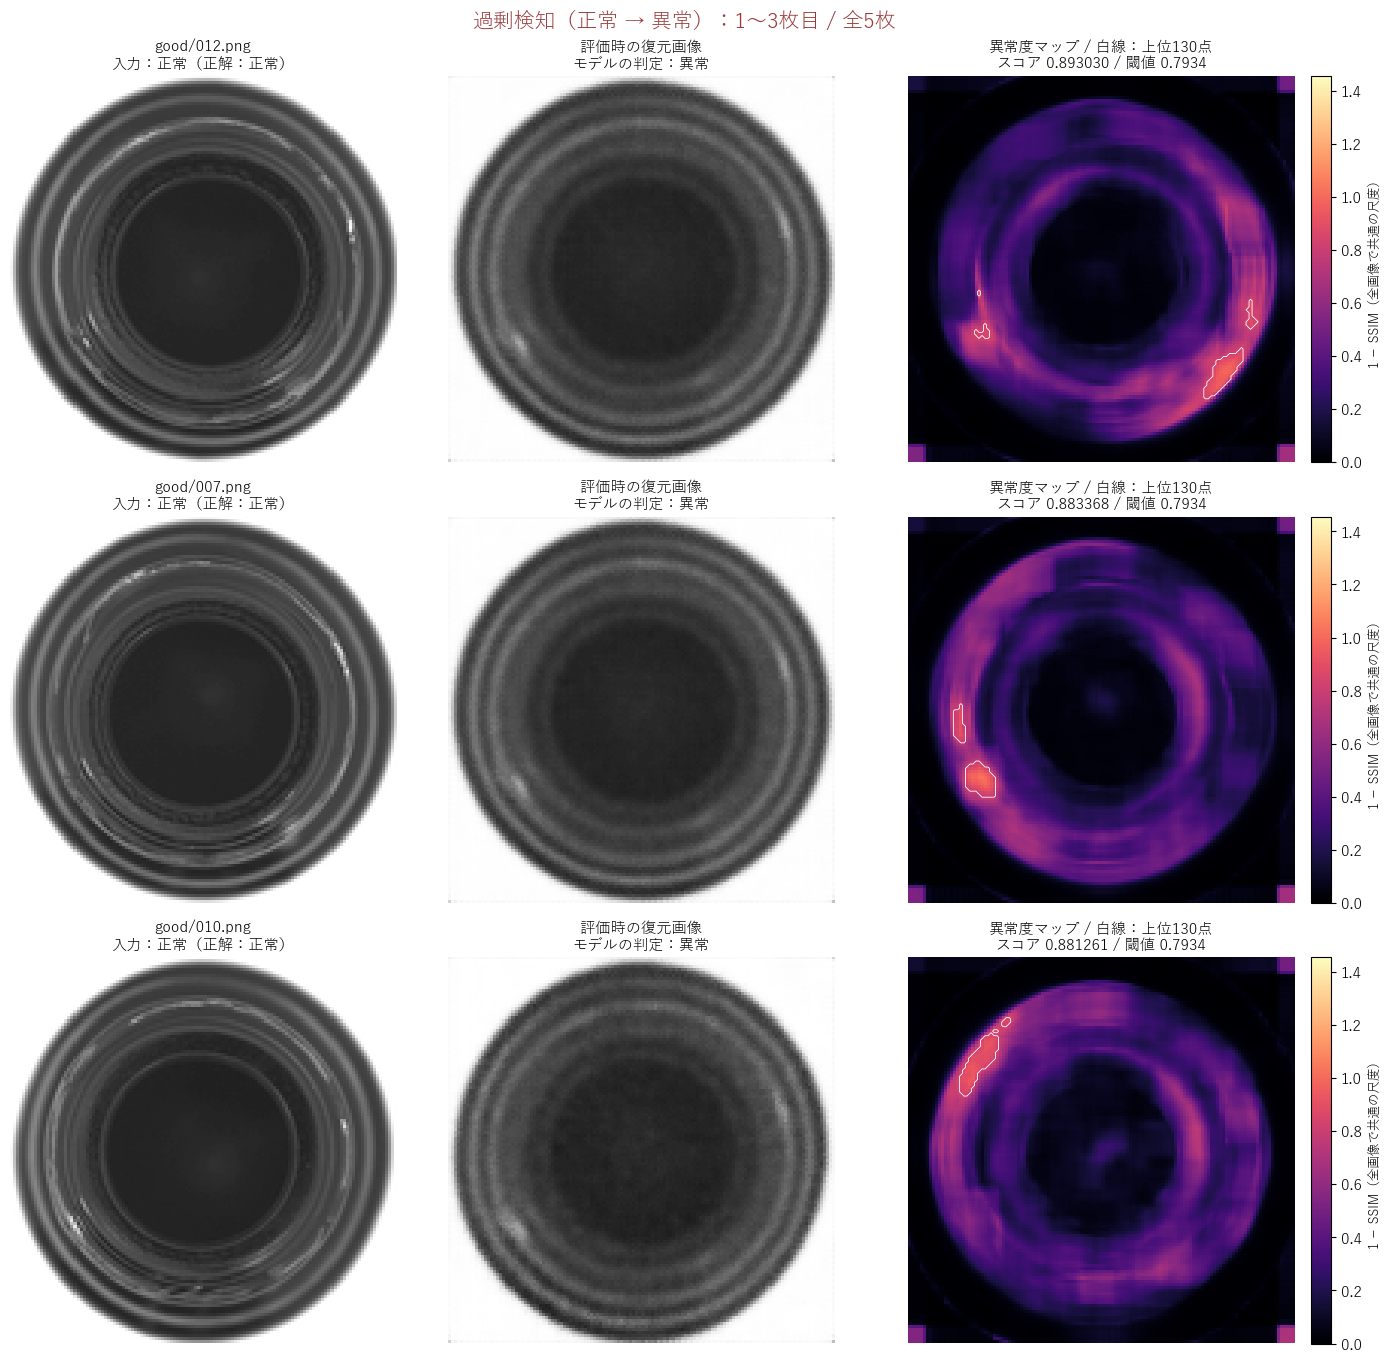

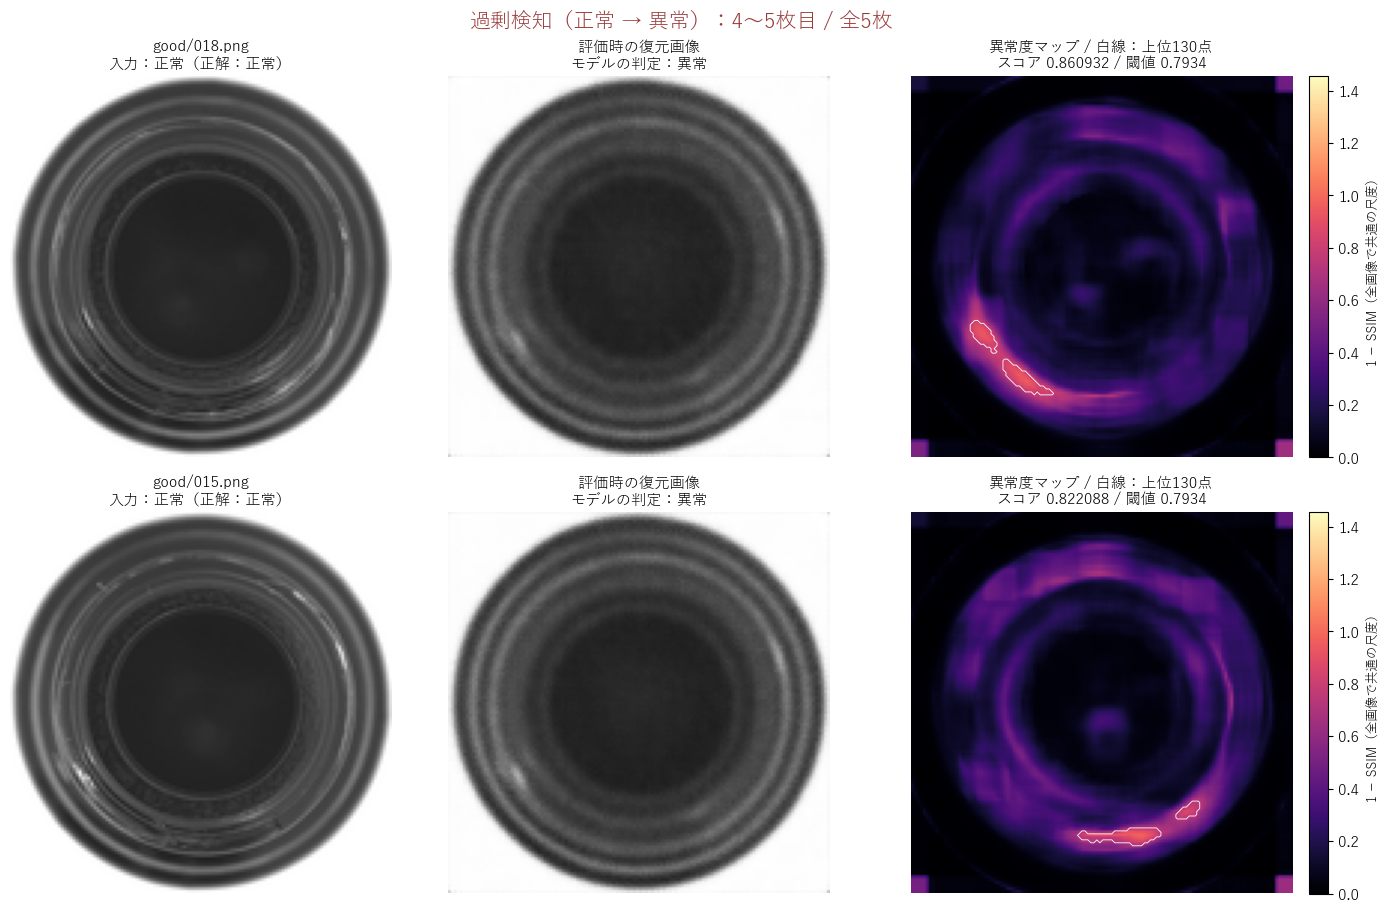

In [7]:
display_error_images(fp_rows, '過剰検知（正常 → 異常）')

## 7. 全画像のスコア一覧

ファイルは data/bottle/test/ からの相対パスです。

この1回の再評価だけで、以前とのAUROCの差をモデルの改善・悪化とは判断しません。重みは同じでも、以前は乱数・画像順が固定されていませんでした。独立に決めた閾値での評価や、複数の乱数でのばらつきの確認は、別途検討します。

In [8]:
display(results[['relative_path', 'category_ja', 'score', 'pred_label', 'outcome']]
        .rename(columns={'relative_path': 'ファイル', 'category_ja': '実際の種類',
                         'score': '異常スコア', 'pred_label': '予測（0正常・1異常）', 'outcome': '分類'})
        .style.format({'異常スコア': '{:.6f}'}))
print(f'AUROC: {auroc:.6f}')
print(f'固定閾値: {THRESHOLD:.4f} / 見逃し: {len(fn_rows)}枚 / 過剰検知: {len(fp_rows)}枚')

,ファイル,実際の種類,異常スコア,予測（0正常・1異常）,分類
0,broken_large/000.png,大きな破損,1.180940,1,TP: 異常を異常と判定
1,broken_large/001.png,大きな破損,1.122858,1,TP: 異常を異常と判定
2,broken_large/002.png,大きな破損,1.245055,1,TP: 異常を異常と判定
3,broken_large/003.png,大きな破損,1.161076,1,TP: 異常を異常と判定
4,broken_large/004.png,大きな破損,1.070069,1,TP: 異常を異常と判定
5,broken_large/005.png,大きな破損,1.138339,1,TP: 異常を異常と判定
6,broken_large/006.png,大きな破損,1.167388,1,TP: 異常を異常と判定
7,broken_large/007.png,大きな破損,1.160503,1,TP: 異常を異常と判定
8,broken_large/008.png,大きな破損,1.155296,1,TP: 異常を異常と判定
9,broken_large/009.png,大きな破損,0.978402,1,TP: 異常を異常と判定


AUROC: 0.969841
固定閾値: 0.7934 / 見逃し: 3枚 / 過剰検知: 5枚
